#### Simple Linear Regression

1. divide the feature based on independent and dependent feature
2. train test split of the dataset
3. standardize the dataset
4. select and train the model

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [4]:
df = pd.read_csv("weight-height.csv")
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


Text(0, 0.5, 'Height')

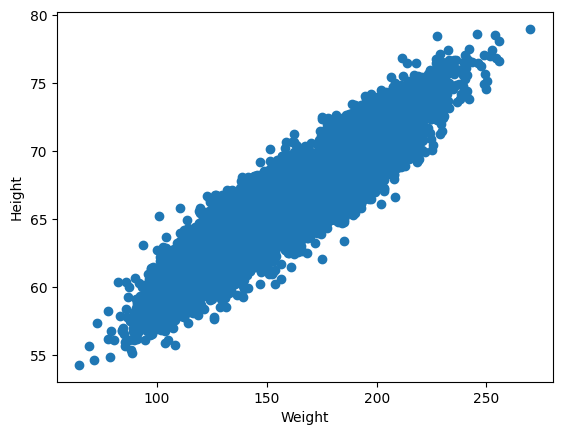

In [6]:
plt.scatter(df['Weight'], df['Height'])
plt.xlabel('Weight')
plt.ylabel("Height")

divide out dataset into independent and dependent feature

In [32]:
X = df[['Weight']]   #independent feature
y= df['Height']  #dependent feature

In [33]:
##train test split
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42)

In [34]:
X.shape, y.shape

((10000, 1), (10000,))

In [35]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((8000, 1), (2000, 1), (8000,), (2000,))

In [43]:
##standardize the dataset train independent data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [ ]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [47]:
#train the simple linear regression model
from sklearn.linear_model import LinearRegression
regression = LinearRegression()
regression.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3.55]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,66.36
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[89.44]


In [52]:
print("The Slope or coeffcient of weight is: ",regression.coef_)
print("Intercept: ", regression.intercept_ )

The Slope or coeffcient of weight is:  [3.55479288]
Intercept:  66.3596814074891


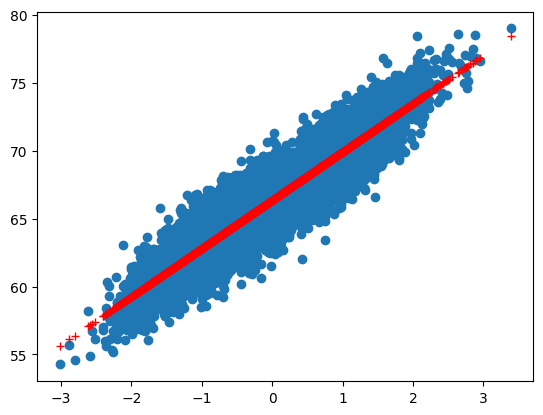

In [57]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train), 'r+')

### prediction of train data
1. predicted height output = intercept +coef_(Weight)
2. y_pred_train =  66.3596 + 3.55(X_train)
   
### prediction of test data
1. predicted height output = intercept +coef_(Weight)
2. y_pred_test =  66.3596 + 3.55(X_test)

In [59]:
Y_pred_test = regression.predict(X_test)
Y_pred_test

array([681.75053935, 760.12031903, 671.44746477, ..., 511.34644879,
       733.14460146, 430.6160615 ], shape=(2000,))

In [60]:
y_test

6252    68.687232
4684    68.829334
1731    66.398128
4742    71.929340
4521    67.042903
          ...    
6412    65.748601
8285    60.731857
7853    62.188933
1095    67.068304
6929    58.632720
Name: Height, Length: 2000, dtype: float64

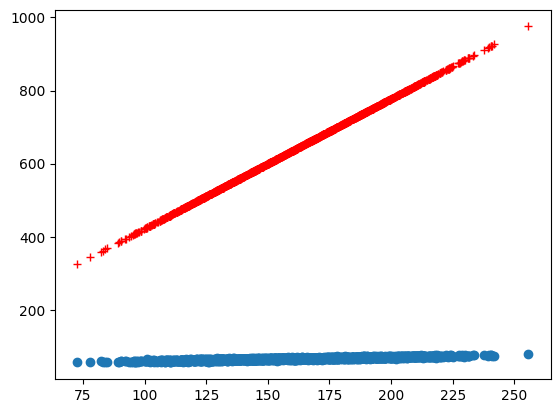

In [61]:
plt.scatter(X_test, y_test)
plt.plot(X_test, regression.predict(X_test), 'r+')

In [62]:
##performance metrics
##calculating mse, mae, rmse
# r square, adjusted r square
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [63]:
mse = mean_squared_error(y_test, Y_pred_test)
mae = mean_absolute_error(y_test, Y_pred_test)
rmse = np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

343585.753559447
575.4628591817695
586.1618834071753


In [64]:
from sklearn.metrics import r2_score
score = r2_score(y_test, Y_pred_test)
score

-23126.553130367633

Adjusted R Square

In [65]:
1 - (1-score)* (len(y_test) -1) /(len(y_test)-X_test.shape[1] -1)

-23138.128482284734